# Runner-up score margin on fresh FMA tracks

This study asks whether the gap between a song's best fingerprint match and the best match from a **different song** can help decide when to show a title.

For a fair comparison, we calibrated two rules on the same fresh development tracks. Both aim to maximise correct acceptance of known songs while allowing at most 1% empirical false acceptance among missing songs. The score-only threshold and the score-plus-margin thresholds were frozen before evaluating the separate test tracks.

The query cohort was generated from 2,048 FMA tracks excluded from the original training pairs, the earlier standard and TikTok-like query archives, and the earlier unknown-song study. The ordered track IDs for both cohorts are saved in reports/runner-up-margin-cohort-tracks.csv. It contains 4,096 synthetic queries, one standard and one TikTok-like query per track. The scorer exhaustively compared each query against every available reference window on the RTX 4090, reduced each window to its track's maximum cosine score, and selected the top two distinct tracks.

Run this notebook from the repository root. It reproduces the reported tables and figure from the committed per-query scores. To rerun MuQ feature generation and GPU scoring, use the three commands documented at the top of `scripts/runner_up_study.py` in the medium CUDA environment.

In [1]:
from pathlib import Path
import json
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "reports").exists():
    ROOT = ROOT.parent

scores_path = ROOT / "reports/runner-up-margin-scores.csv.gz"
results_path = ROOT / "reports/runner-up-margin.json"
scores = pd.read_csv(scores_path)
results = json.loads(results_path.read_text())

assert len(scores) == 4096
assert scores.track_id.nunique() == 2048
assert (scores.exact_track != scores.runner_up_track).all()
assert (scores.exact_score >= scores.runner_up_score).all()
assert ((scores.exact_score - scores.runner_up_score - scores.score_margin).abs() < 2e-8).all()

print(results["data"])
print("Head thresholds selected on development tracks:")
print(json.dumps(results["threshold_selection"], indent=2))

{'queries': 4096, 'unique_tracks': 2048, 'queries_per_track': 2, 'removed_tracks': 1024, 'reference_windows': 105767, 'reference_tracks': 23946, 'split_track_counts': {'development_False': 512, 'development_True': 512, 'test_False': 512, 'test_True': 512}}
Head thresholds selected on development tracks:
{
  "max_false_accepts_on_development": 10,
  "maximum_score": {
    "score_threshold": 0.834209919,
    "gap_threshold": null,
    "dev_false_accepts": 10,
    "dev_known_correct_accepts": 551
  },
  "score_and_margin": {
    "score_threshold": 0.749896646,
    "gap_threshold": 0.11748421200000002,
    "dev_false_accepts": 10,
    "dev_known_correct_accepts": 755
  }
}


In [2]:
test = {row["rule_name"]: row for row in results["test"]}
rows = []
for name, label in (
    ("maximum_score", "Maximum score"),
    ("score_and_margin", "Score plus distinct-song margin"),
):
    result = test[name]
    rows.append({
        "rule": label,
        "known correct accepted": f'{result["known_correct_accepted"]}/{result["known_queries"]}',
        "known acceptance": f'{result["known_correct_acceptance_rate"]:.1%}',
        "known accepted incorrectly": result["known_accepted_incorrectly"],
        "unknown false accepted": f'{result["unknown_false_accepts"]}/{result["unknown_queries"]}',
        "unknown false acceptance": f'{result["unknown_false_acceptance_rate"]:.2%}',
        "known 95% track-bootstrap interval": "–".join(f'{x:.1%}' for x in result["known_rate_track_bootstrap_95"]),
        "unknown 95% track-bootstrap interval": "–".join(f'{x:.2%}' for x in result["unknown_rate_track_bootstrap_95"]),
    })
pd.DataFrame(rows)

,rule,known correct accepted,known acceptance,known accepted incorrectly,unknown false accepted,unknown false acceptance,known 95% track-bootstrap interval,unknown 95% track-bootstrap interval
0,Maximum score,538/1024,52.5%,2,4/1024,0.39%,49.7%–55.4%,0.10%–0.78%
1,Score plus distinct-song margin,731/1024,71.4%,0,11/1024,1.07%,68.8%–74.0%,0.39%–1.86%


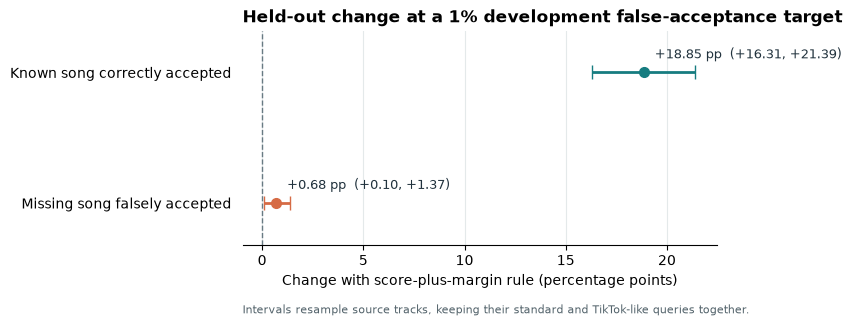

In [3]:
import matplotlib.pyplot as plt

comparison = results["paired_test_comparison"]["all"]
labels = ["Known song correctly accepted", "Missing song falsely accepted"]
keys = ["known_correct_acceptance", "unknown_false_acceptance"]
colors = ["#167C80", "#D66B45"]
fig, ax = plt.subplots(figsize=(8.4, 3.15), layout="constrained")

for position, (label, key, color) in enumerate(zip(labels, keys, colors)):
    item = comparison[key]
    estimate = item["margin_minus_score_percentage_points"]
    low, high = item["paired_track_bootstrap_95_percentage_points"]
    ax.errorbar(
        estimate, position,
        xerr=[[estimate - low], [high - estimate]],
        fmt="o", color=color, ecolor=color, elinewidth=2, capsize=5, markersize=7,
    )
    ax.annotate(
        f"{estimate:+.2f} pp  ({low:+.2f}, {high:+.2f})",
        xy=(estimate, position), xytext=(8, 13), textcoords="offset points",
        va="center", fontsize=9, color="#21323D",
    )

ax.axvline(0, color="#687A83", linewidth=1, linestyle="--")
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set_ylim(1.32, -0.32)
ax.set_xlabel("Change with score-plus-margin rule (percentage points)")
ax.set_title("Held-out change at a 1% development false-acceptance target", loc="left", weight="bold")
ax.grid(axis="x", color="#E4E9EA", linewidth=0.8)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0, pad=8)
ax.text(
    0, -0.32,
    "Intervals resample source tracks, keeping their standard and TikTok-like queries together.",
    transform=ax.transAxes, fontsize=8, color="#53636B",
)

figure_dir = ROOT / "reports/figures"
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / "runner-up-margin.pdf", bbox_inches="tight")
fig.savefig(figure_dir / "runner-up-margin.png", dpi=200, bbox_inches="tight")
plt.show()

## Read the result carefully

The gap rule improved correct acceptance on the held-out known songs by **18.85 percentage points** (paired 95% track-bootstrap interval **16.31 to 21.39**). Its held-out unknown false-acceptance rate also increased by **0.68 points** (paired interval **0.10 to 1.37**). It accepted 11 of 1,024 missing-song queries, one above the 10-query development budget. The maximum-score rule accepted 4 of 1,024 missing songs and correctly accepted 538 of 1,024 known-song queries.

The gap is between each song's best reference window, so adjacent windows of one song cannot become the runner-up. On known songs, the margin rule accepted no wrong titles in this test, compared with two for maximum score. These are promising synthetic-query results, with a measurable false-acceptance cost. They do not yet establish the 1% target on unseen recordings or on physical phone captures.

The source of truth, full family breakdowns, calibrated thresholds and reproduction commands are in `reports/runner-up-margin.json` and `reports/runner-up-margin.md`. The source script validates track exclusion, computes both distinct-song scores on CUDA, calibrates rules on the development songs, and performs the track bootstrap.